# Análisis exploratorio de datos

Un comentario previo es que para cuidar el leakage que suele ocurrir en este tipo de análisis, desde un inicio se hizo un split de 80% / 20% para que el EDA no esté sesgado viendo todos los hogares. Este análisis exploratorio solamente analizará el 80% de los datos, usando "train.parquet"

In [1]:
# Obtener los datos de train 
import pandas as pd

train = pd.read_parquet("../data/interim/train.parquet")
train[["folioviv", "foliohog", "id_hogar"]].head()

,folioviv,foliohog,id_hogar
0,1304572922,1,13045729221
1,0361134718,1,03611347181
2,0762623024,1,07626230241
3,2167058718,1,21670587181
4,0300840506,1,03008405061


### Primera aclaración 

**ID_HOGAR**

Se creó la variable id_hogar, porque la ENIGH tiene folio vivienda y folio hogar, sin embargo, una misma vivienda puede tener más de un hogar (como se vio en el notebook de exploración). De forma que para obtener un id que identifica a cada hogar se necesita aplicar la siguiente construcción: 

id_hogar = folio vivienda + folio hogar 

Y así queda un valor único para cada hogar. 

### Tamaño de la base de datos 

Podemos ver que son 73,131 observaciones y son 127 variables 

In [2]:
print(train.shape) 

(73131, 127)


In [3]:
# Valores de id_hogar repetidos, esto es importante porque debería ser un identificador único 

# ¿Cuántos id_hogar están repetidos?
n_dup = train["id_hogar"].duplicated().sum()
print(f"Duplicados en id_hogar: {n_dup}")


Duplicados en id_hogar: 0


In [4]:
# ¿Hay filas completamente identicas?
print(f"Filas totalmente duplicadas: {train.duplicated().sum()}")

Filas totalmente duplicadas: 0


### Creación de variable objetivo 

Con 127 variables, hacer un EDA especifico para cada variable, no tiene sentido. Entonces, el EDA se centrará en la creación de la variable objetivo: **gasto catastrófico**. Y no hay riesgo de leakage en construirla primero porque la definición viene de la literatura y no de los datos. 

La definición de la variable objetivo es: 

Gasto catastrófico = 1 si Gasto en salud / Ingreso disponible  > 30%
donde ingreso disponible = ingreso del hogar - gasto en alimentos  

**Notas:**

 * Ingreso disponible = ing_cor - ali_dentro
 * Población de análisis: solo hogares con ingreso disponible >0
 * Etiqueta = 1 si salud / ingreso disponible > 30%

In [5]:
# Revisando las variables de interés

import numpy as np
import matplotlib.pyplot as plt

cols = ["ing_cor", "ali_dentro", "salud", "factor"]
d = train[cols]

# 1. Tipos y nulos
print(d.dtypes)
print(d.isna().sum())

# No hay valores nulos


ing_cor       float64
ali_dentro    float64
salud         float64
factor          int64
dtype: object
ing_cor       0
ali_dentro    0
salud         0
factor        0
dtype: int64


In [6]:
# 2. Resumen con percentiles (los extremos importan)
print(d.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T)

              count          mean           std  min        1%         5%  \
ing_cor     73131.0  72525.834637  99765.349097  0.0  9001.474  16207.590   
ali_dentro  73131.0  13106.776989   8766.829828  0.0     0.000   2494.245   
salud       73131.0   1524.790709   6193.446473  0.0     0.000      0.000   
factor      73131.0    423.847807    472.544337  4.0    16.000     35.000   

                  25%       50%       75%         95%         99%          max  
ing_cor     34574.865  55688.39  88869.44  175698.875  311149.057  17431977.54  
ali_dentro   7071.360  11532.72  17241.32   28889.880   42282.961    164709.68  
salud           0.000    187.81   1037.43    5958.570   21505.872    314999.97  
factor        141.000    288.00    526.00    1299.000    2256.000      7127.00  


In [7]:
# 3. Ceros y negativos
print(pd.DataFrame({
    "ceros": (d == 0).sum(),
    "pct_cero": (d == 0).mean().round(3),
    "negativos": (d < 0).sum(),
}))

            ceros  pct_cero  negativos
ing_cor         4      0.00          0
ali_dentro    736      0.01          0
salud       27805      0.38          0
factor          0      0.00          0


In [8]:
# 4. Ingreso disponible y gasto en salud
disp = train["ing_cor"] - train["ali_dentro"]
print("Ingreso disponible <= 0:", (disp <= 0).sum(), f"({(disp <= 0).mean():.2%})")
print("Hogares con gasto en salud > 0:", f"{(train['salud'] > 0).mean():.2%}")



Ingreso disponible <= 0: 906 (1.24%)
Hogares con gasto en salud > 0: 61.98%


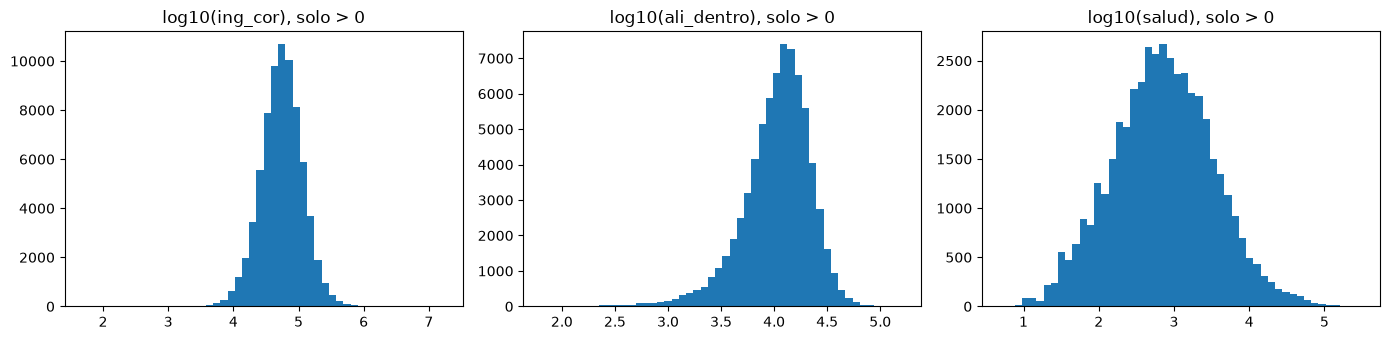

In [9]:
# 5. Distribuciones (escala log, solo valores > 0)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, c in zip(axes, ["ing_cor", "ali_dentro", "salud"]):
    x = train.loc[train[c] > 0, c]
    ax.hist(np.log10(x), bins=50)
    ax.set_title(f"log10({c}), solo > 0")
plt.tight_layout()

### ¿Qué estamos viendo? 

1. No hay valores nulos, el tipo de dato es correcto y en factor no hay ceros, así que el tema de la ponderación no tendrá problema 

2. Solo hay 4 hogares con ingreso igual a cero y 906 con ingreso disponible igual a cero. Excluirlos cambia poco la muestra y no perdemos tanta representatividad. 

3. No hay ningún valor negativo en nada 


In [10]:
disp = train["ing_cor"] - train["ali_dentro"]
excl = train[disp <= 0]
print("Excluidos con salud > 0:", (excl["salud"] > 0).sum(), f"({(excl['salud'] > 0).mean():.1%})")
print("Peso poblacional excluido:", excl["factor"].sum() / train["factor"].sum())

Excluidos con salud > 0: 532 (58.7%)
Peso poblacional excluido: 0.009813683608690992


### ¿Qué pasa con los hogares que no tienen ingreso disponible? (906 hogares)

Podemos ver que excluirlos realmente no es costoso en términos poblacionales, esos hogares solamente representan el 0.98% de la población (ponderada), prácticamente igual que su 1.24% en la muestra. Lo que nos da luz verde para quitarlos sin esperar que cambien las conclusiones generales. 

Por otro lado, vemos que de esos 906 hogares, el 58.7% sí tuvo un gasto en salud, con ingreso disponible nulo o negativo. Lo que nos habla de hogares en una situación financiera extrema, que nuestro estudio no está contemplado (solo para tenerlo presente). Podríamos dejar estos hogares pendientes para un análisis de sensibilidad. 

In [11]:
import sys
sys.path.append("..")  # para poder importar desde src/
from src.etiqueta import construir_etiqueta

df = construir_etiqueta(train)
y = df["gasto_catastrofico"].astype(int)

print("Prevalencia sin ponderar:", y.mean())
print("Prevalencia ponderada:   ", (y * df["factor"]).sum() / df["factor"].sum())

Hogares con ingreso disponible <= 0: 2,715 (3.71%)
Prevalencia sin ponderar: 0.03502044989775051
Prevalencia ponderada:    0.03353396929745337


### ¿Qué estamos viendo? 

* La prevalencia es aproximadamente 2.05% sin ponderar y 1.84% ponderado. 
* Hay un desbalance de clases fuerte: aproximadamente 1 positivo por cada 48 hogares. Así que hay considerar métricas que consideren este desbalance

### Decisiones por definir 

1. La construcción con la definición teórica en lugar de con los datos 
2. Mantener o quitar la regla de hogares con ingreso disponible positivo 
3. El uso de ingreso corriente total aunque incluye componentes no monetarios (como el alquiler estimado)

### ¿Ingreso corriente o monetario? 

En el catálogo se están usando varias cosas no monetarias que componen el ingreso corriente, tal vez, lo mejor sea quitarlas. Vemos como el incluir esos elementos inflan el ingreso y causa que la prevalencia disminuya. Cuando cambiamos la definición, ya tenemos más positivos para modelar y eso puede ayudar a la estabilidad del modelo y de la validación cruzada

In [15]:
from src.etiqueta import construir_etiqueta, COMPONENTES_NO_MONETARIOS

# ¿Qué fracción del ingreso corriente era no monetaria?
no_mon = train[COMPONENTES_NO_MONETARIOS].sum(axis=1)
print((no_mon / train["ing_cor"].where(train["ing_cor"] > 0)).describe())



count    73127.000000
mean         0.193543
std          0.159421
min          0.000000
25%          0.086158
50%          0.154495
75%          0.257667
max          1.000000
dtype: float64


In [13]:
df_all = construir_etiqueta(train, excluir=False)
excl = df_all[df_all["ing_disponible"] <= 0]
print("Excluidos con salud > 0:", (excl["salud"] > 0).sum(), f"({(excl['salud'] > 0).mean():.1%})")
print("Peso poblacional excluido:", excl["factor"].sum() / df_all["factor"].sum())

Hogares con ingreso disponible <= 0: 2,715 (3.71%)
Excluidos con salud > 0: 1559 (57.4%)
Peso poblacional excluido: 0.031060012296906345


## Columnas candidatas 

Después de clasificar las variables para identificar aquellas que podrían poner en riesgo el estudio, se encontraron 16 variables candidatas: 

    "tam_loc", "est_socio", "clase_hog", "sexo_jefe", "edad_jefe", "educa_jefe",
    "tot_integ", "hombres", "mujeres", "mayores", "menores", "p12_64", "p65mas",
    "ocupados", "percep_ing", "perc_ocupa"




In [16]:
import pandas as pd
from src.etiqueta import construir_etiqueta

df = construir_etiqueta(train)
df["y"] = df["gasto_catastrofico"].astype(int)
df["yw"] = df["y"] * df["factor"]              # para tasas ponderadas
df["entidad"] = df["folioviv"].str[:2]

# Agrupaciones fijadas a priori (no se eligen mirando la etiqueta)
df["edad_jefe_gpo"] = pd.cut(df["edad_jefe"], [0, 29, 44, 59, 74, 120],
                             labels=["<30", "30-44", "45-59", "60-74", "75+"])
for c in ["tot_integ", "menores", "p65mas", "ocupados", "percep_ing"]:
    df[c + "_gpo"] = df[c].clip(upper=4)       # 4 significa "4 o más"

def tasa_por_grupo(col):
    g = df.groupby(col, observed=True)
    return pd.DataFrame({
        "hogares": g.size(),
        "positivos": g["y"].sum(),
        "pct_poblacion": g["factor"].sum() / df["factor"].sum(),
        "tasa_pond": g["yw"].sum() / g["factor"].sum(),
    }).round(4)

print("Tasa ponderada global:", round(df["yw"].sum() / df["factor"].sum(), 4))

for col in ["tam_loc", "est_socio", "clase_hog", "sexo_jefe", "educa_jefe",
            "edad_jefe_gpo", "tot_integ_gpo", "menores_gpo", "p65mas_gpo",
            "ocupados_gpo", "percep_ing_gpo", "entidad"]:
    print(f"\n=== {col} ===")
    display(tasa_por_grupo(col))

Hogares con ingreso disponible <= 0: 2,715 (3.71%)
Tasa ponderada global: 0.0335

=== tam_loc ===


,hogares,positivos,pct_poblacion,tasa_pond
tam_loc,,,,
1,26990,538,0.5044,0.0219
2,8206,281,0.1541,0.0338
3,8258,325,0.1441,0.0365
4,26962,1322,0.1973,0.0609



=== est_socio ===


,hogares,positivos,pct_poblacion,tasa_pond
est_socio,,,,
1,14025,677,0.1489,0.0552
2,35807,1289,0.4630,0.0348
3,14078,365,0.2462,0.0245
4,6506,135,0.1420,0.0223



=== clase_hog ===


,hogares,positivos,pct_poblacion,tasa_pond
clase_hog,,,,
1,9373,495,0.1328,0.0558
2,43550,1423,0.6132,0.0301
3,16793,537,0.2438,0.0307
4,447,11,0.0063,0.0284
5,253,0,0.0039,0.0000


... (14 outputs left out)


=== percep_ing_gpo ===


,hogares,positivos,pct_poblacion,tasa_pond
percep_ing_gpo,,,,
1,20922,915,0.2952,0.0438
2,26576,977,0.3747,0.0343
3,13820,372,0.2005,0.0245
4,9098,202,0.1296,0.0220



=== entidad ===


,hogares,positivos,pct_poblacion,tasa_pond
entidad,,,,
01,2292,54,0.0115,0.0215
02,3191,30,0.0312,0.0085
03,2185,36,0.0072,0.0110
04,1691,57,0.0069,0.0358
05,3235,58,0.0266,0.0162
06,2602,76,0.0064,0.0224
07,1630,88,0.0383,0.0519
08,3666,73,0.0315,0.0154
09,2013,53,0.0803,0.0262
